# Machine Learning Assignment 2 — Bank Marketing
Name:   Tony Baby   
BITSID: 2026ak05659

In [ ]:
%pip install scipy==1.15.3

In [ ]:
%pip install scikit-learn==1.8.0

## 1. Imports and random seed

In [1]:
from pathlib import Path
import hashlib
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    ConfusionMatrixDisplay, classification_report,
)

SEED = 346234
np.random.seed(SEED)
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False})
print('Python:', platform.python_version())
for package in [np, pd, scipy, sklearn, joblib]:
    print(f'{package.__name__}: {package.__version__}')

Python: 3.12.3
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
sklearn: 1.8.0
joblib: 1.5.3


## 2. Load the dataset
[UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing): `bank-additional.csv`, containing 4,119 records and 20 original predictors. The checksum verifies the official data file.

In [ ]:
data_path = Path('data/bank-additional.csv')
df = pd.read_csv(data_path, sep=';')
assert df.shape == (4119, 21)
assert df['y'].value_counts().to_dict() == {'no': 3668, 'yes': 451}
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (4119, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8000,92.8930,-46.2000,1.3130,5099.1000,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8550,5191.0000,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4000,94.4650,-41.8000,4.9620,5228.1000,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4000,94.4650,-41.8000,4.9590,5228.1000,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1000,93.2000,-42.0000,4.1910,5195.8000,no


## 3. Inspect the data
Check feature types, target counts, missing values, and duplicates. Literal `unknown` values are retained as categories.

In [3]:
display(pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'unique_values': df.nunique(),
    'missing_cells': df.isna().sum(),
    'literal_unknown': df.eq('unknown').sum(),
}))
class_counts = df['y'].value_counts().reindex(['no', 'yes'])
display(pd.DataFrame({'count': class_counts, 'percent': 100 * class_counts / len(df)}))
print('Exact duplicate full rows:', df.duplicated().sum())
print('Actual missing cells:', df.isna().sum().sum())

,dtype,unique_values,missing_cells,literal_unknown
age,int64,67,0,0
job,object,12,0,39
marital,object,4,0,11
education,object,8,0,167
default,object,3,0,803
housing,object,3,0,105
loan,object,3,0,105
contact,object,2,0,0
month,object,10,0,0
day_of_week,object,5,0,0


,count,percent
y,,
no,3668,89.0507
yes,451,10.9493


Exact duplicate full rows: 0
Actual missing cells: 0


## 4. Exploratory data analysis
Examine the class distribution, age, and campaign contacts.

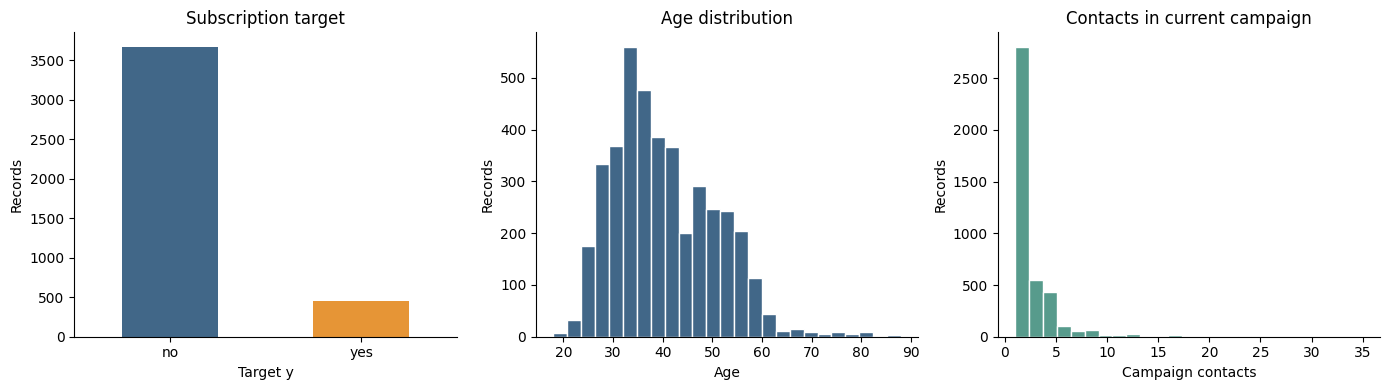

,age,campaign,previous,euribor3m
count,4119.0000,4119.0000,4119.0000,4119.0000
mean,40.1136,2.5373,0.1903,3.6214
std,10.3134,2.5682,0.5418,1.7336
min,18.0000,1.0000,0.0000,0.6350
25%,32.0000,1.0000,0.0000,1.3340
50%,38.0000,2.0000,0.0000,4.8570
75%,47.0000,3.0000,0.0000,4.9610
max,88.0000,35.0000,6.0000,5.0450


Always predicting no gives 89.05% accuracy on the full data.
Accuracy alone can hide poor detection of the minority yes class.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
class_counts.plot.bar(ax=axes[0], color=['#416788', '#e69536'], rot=0)
axes[0].set(title='Subscription target', xlabel='Target y', ylabel='Records')
axes[1].hist(df['age'], bins=25, color='#416788', edgecolor='white')
axes[1].set(title='Age distribution', xlabel='Age', ylabel='Records')
axes[2].hist(df['campaign'], bins=25, color='#579b8c', edgecolor='white')
axes[2].set(title='Contacts in current campaign', xlabel='Campaign contacts', ylabel='Records')
plt.tight_layout()
plt.show()

display(df[['age', 'campaign', 'previous', 'euribor3m']].describe())
print(f'Always predicting no gives {class_counts["no"] / len(df):.2%} accuracy on the full data.')
print('Accuracy alone can hide poor detection of the minority yes class.')

## 5. Prepare the inputs
Remove `duration` because it is known only after the call. Treat `pdays` as categorical since 999 means no previous contact. Encode the target as `no=0` and `yes=1`.

For reproducible grouping, use numeric columns followed by categorical columns, with `pdays` converted to text before hashing.

In [5]:
numeric_features = [
    'age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx',
    'cons.conf.idx', 'euribor3m', 'nr.employed',
]
categorical_features = [
    'job', 'marital', 'education', 'default', 'housing', 'loan',
    'contact', 'month', 'day_of_week', 'poutcome', 'pdays',
]
X = df.drop(columns=['duration', 'y'])[numeric_features + categorical_features].copy()
X['pdays'] = X['pdays'].astype(str)
y = df['y'].map({'no': 0, 'yes': 1})
assert X.shape[1] == 19
assert set(X.columns) == set(numeric_features + categorical_features)
assert y.notna().all()

groups = pd.util.hash_pandas_object(X, index=False)
print('Predictors in hashing order:', X.columns.tolist())
print('Repeated predictor rows beyond first occurrence:', X.duplicated().sum())
print('Distinct predictor groups:', groups.nunique())
print('Predictor groups with conflicting targets:',
      pd.DataFrame({'group': groups, 'y': y}).groupby('group')['y'].nunique().gt(1).sum())

Predictors in hashing order: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'pdays']
Repeated predictor rows beyond first occurrence: 20
Distinct predictor groups: 4099
Predictor groups with conflicting targets: 1


## 6. Split training and test data
Use the first fold of a five-fold `StratifiedGroupKFold`: 3,295 training rows and 824 test rows. Identical predictor rows remain in the same partition. The test set is reserved for final evaluation.

In [ ]:
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_index, test_index = next(outer_split.split(X, y, groups))
X_train, X_test = X.iloc[train_index].copy(), X.iloc[test_index].copy()
y_train, y_test = y.iloc[train_index].copy(), y.iloc[test_index].copy()
groups_train = groups.iloc[train_index]

display(pd.DataFrame({
    'rows': [len(y_train), len(y_test)],
    'no': [y_train.eq(0).sum(), y_test.eq(0).sum()],
    'yes': [y_train.eq(1).sum(), y_test.eq(1).sum()],
}, index=['Training', 'Frozen test']))

,rows,no,yes
Training,3295,2934,361
Frozen test,824,734,90


No identical predictor groups cross the train/test boundary.


## 7. Preprocessing
- Numeric: median imputation and standard scaling.
- Categorical: most-frequent imputation and dense one-hot encoding.

Each model uses a separate pipeline. Preprocessing is fitted within training folds during cross-validation.

In [7]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
], sparse_threshold=0)

## 8. Train the classifiers
Fit Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, and SVM on the same training data.

In [8]:
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=10,
                                          class_weight='balanced', random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=11),
    'Gaussian Naive Bayes': GaussianNB(),
    'SVM': SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED),
}
models = {}
for name, classifier in classifiers.items():
    model = Pipeline([('preprocessor', clone(preprocessor)), ('classifier', classifier)])
    model.fit(X_train, y_train)
    models[name] = model
    print('Fitted:', name)

Fitted: Logistic Regression
Fitted: Decision Tree
Fitted: KNN
Fitted: Gaussian Naive Bayes


Fitted: SVM


## 9. Cross-validation and model selection
Compare macro F1 using three grouped, stratified folds on the training data. Select the model with the highest mean score before evaluating the test set.

In [9]:
inner_split = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_folds = list(inner_split.split(X_train, y_train, groups_train))
for fold_train, fold_valid in cv_folds:
    assert set(groups_train.iloc[fold_train]).isdisjoint(set(groups_train.iloc[fold_valid]))

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv_folds,
                             scoring='f1_macro', n_jobs=1, error_score='raise')
    cv_rows.append({'Model': name, 'Fold 1': scores[0], 'Fold 2': scores[1],
                    'Fold 3': scores[2], 'CV macro F1': scores.mean(), 'Std': scores.std()})
cv_results = pd.DataFrame(cv_rows).set_index('Model')
cv_winner = cv_results['CV macro F1'].idxmax()
display(cv_results.sort_values('CV macro F1', ascending=False))
print(f'Winner selected using training CV only: {cv_winner} '
      f'({cv_results.loc[cv_winner, "CV macro F1"]:.4f})')

,Fold 1,Fold 2,Fold 3,CV macro F1,Std
Model,,,,,
SVM,0.6705,0.6942,0.6720,0.6789,0.0108
Logistic Regression,0.6563,0.6458,0.6521,0.6514,0.0043
Decision Tree,0.6131,0.6507,0.6521,0.6386,0.0181
KNN,0.6329,0.6023,0.6416,0.6256,0.0169
Gaussian Naive Bayes,0.3057,0.6925,0.6413,0.5465,0.1716


Winner selected using training CV only: SVM (0.6789)


## 10. Test-set evaluation
Calculate accuracy, ROC AUC, macro precision, macro recall, macro F1, and MCC. AUC uses the probability of `yes=1`; the other metrics use `predict` labels.

In [10]:
predictions, probabilities, test_rows = {}, {}, []
for name, model in models.items():
    predictions[name] = model.predict(X_test)
    positive_index = list(model.classes_).index(1)
    probabilities[name] = model.predict_proba(X_test)[:, positive_index]
    test_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions[name]),
        'AUC': roc_auc_score(y_test, probabilities[name]),
        'Precision': precision_score(y_test, predictions[name], average='macro', zero_division=0),
        'Recall': recall_score(y_test, predictions[name], average='macro', zero_division=0),
        'F1': f1_score(y_test, predictions[name], average='macro', zero_division=0),
        'MCC': matthews_corrcoef(y_test, predictions[name]),
    })
results = pd.DataFrame(test_rows).set_index('Model')
display(results)
print(f'Frozen-test majority-class accuracy: {y_test.eq(0).mean():.2%}')
print('This baseline detects zero subscribers; compare the class reports as well as accuracy.')

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8216,0.7590,0.6363,0.7244,0.6590,0.3498
Decision Tree,0.7828,0.7279,0.6083,0.7026,0.6224,0.2963
KNN,0.8944,0.6899,0.7404,0.5557,0.5727,0.2314
Gaussian Naive Bayes,0.7864,0.7459,0.6087,0.6998,0.6235,0.2948
SVM,0.8422,0.7587,0.6442,0.7018,0.6642,0.3412


Frozen-test majority-class accuracy: 89.08%
This baseline detects zero subscribers; compare the class reports as well as accuracy.


## 11. Confusion matrices and classification reports
Matrix rows show actual classes and columns show predictions: `[[TN, FP], [FN, TP]]`. The `yes` row in each report measures subscriber detection.

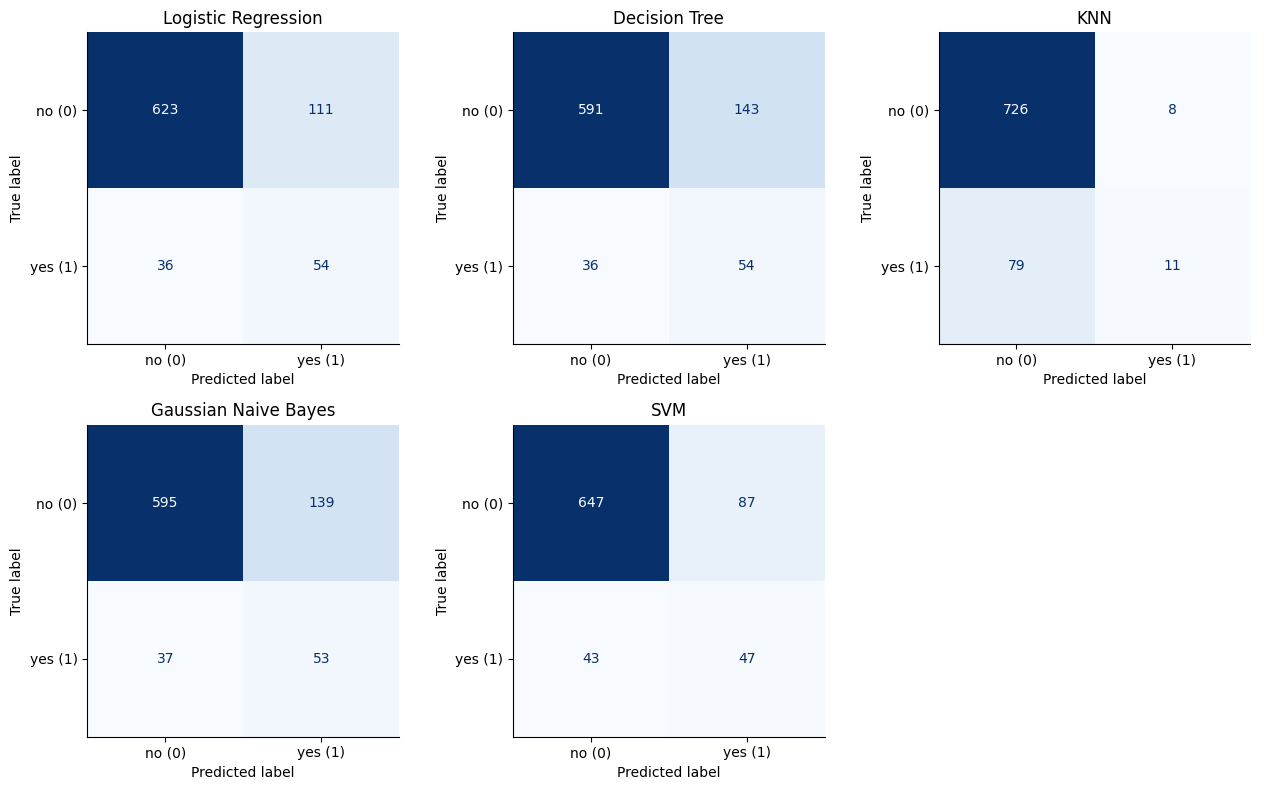


Logistic Regression


              precision    recall  f1-score   support

          no     0.9454    0.8488    0.8945       734
         yes     0.3273    0.6000    0.4235        90

    accuracy                         0.8216       824
   macro avg     0.6363    0.7244    0.6590       824
weighted avg     0.8779    0.8216    0.8430       824


Decision Tree
              precision    recall  f1-score   support

          no     0.9426    0.8052    0.8685       734
         yes     0.2741    0.6000    0.3763        90

    accuracy                         0.7828       824
   macro avg     0.6083    0.7026    0.6224       824
weighted avg     0.8696    0.7828    0.8147       824


KNN
              precision    recall  f1-score   support

          no     0.9019    0.9891    0.9435       734
         yes     0.5789    0.1222    0.2018        90

    accuracy                         0.8944       824
   macro avg     0.7404    0.5557    0.5727       824
weighted avg     0.8666    0.8944    0.8625       824


,TN,FP,FN,TP,Subscriber recall
Model,,,,,
Logistic Regression,623,111,36,54,0.6000
Decision Tree,591,143,36,54,0.6000
KNN,726,8,79,11,0.1222
Gaussian Naive Bayes,595,139,37,53,0.5889
SVM,647,87,43,47,0.5222


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, predicted) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0, 1],
        display_labels=['no (0)', 'yes (1)'], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

subscriber_rows = []
for name, predicted in predictions.items():
    print(f'\n{name}')
    print(classification_report(y_test, predicted, labels=[0, 1],
          target_names=['no', 'yes'], digits=4, zero_division=0))
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
    subscriber_rows.append({'Model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                            'Subscriber recall': tp / (tp + fn)})
subscriber_results = pd.DataFrame(subscriber_rows).set_index('Model')
display(subscriber_results)

## 12. Save models and test data
Save all five fitted pipelines and export the held-out records to `test_data.csv`. Reload the models and verify their predictions.

In [12]:
model_directory = Path('model')
model_directory.mkdir(exist_ok=True)
model_files = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'KNN': 'knn.joblib',
    'Gaussian Naive Bayes': 'gaussian_nb.joblib',
    'SVM': 'svm.joblib',
}
for name, model in models.items():
    path = model_directory / model_files[name]
    joblib.dump(model, path)
    reloaded = joblib.load(path)
    np.testing.assert_array_equal(reloaded.predict(X_test), predictions[name])
    np.testing.assert_allclose(reloaded.predict_proba(X_test), model.predict_proba(X_test))
    print('Saved and verified:', path)

test_data = X_test.copy()
test_data['y'] = y_test.map({0: 'no', 1: 'yes'})
test_data.to_csv('test_data.csv', index=False)
round_trip = pd.read_csv('test_data.csv', dtype={col: str for col in categorical_features})
assert round_trip.shape == (len(X_test), 20)
for name, model in models.items():
    np.testing.assert_array_equal(model.predict(round_trip[X.columns]), predictions[name])
print('Exported test_data.csv:', round_trip.shape)

Saved and verified: model/logistic_regression.joblib
Saved and verified: model/decision_tree.joblib


Saved and verified: model/knn.joblib


Saved and verified: model/gaussian_nb.joblib


Saved and verified: model/svm.joblib
Exported test_data.csv: (824, 20)


## 13. Results and observations

Logistic Regression: test macro F1=0.6590; detected 54 of 90 subscribers (60.00%); 111 false positives.
A linear, balanced baseline; compare recovered subscribers with false-positive calls. 

Decision Tree: test macro F1=0.6224; detected 54 of 90 subscribers (60.00%); 143 false positives.
Depth and leaf limits keep the tree manageable, but its threshold rules can be unstable. 

KNN: test macro F1=0.5727; detected 11 of 90 subscribers (12.22%); 8 false positives.
Neighbour voting can favour the majority class, despite scaling the numeric inputs. 

Gaussian Naive Bayes: test macro F1=0.6235; detected 53 of 90 subscribers (58.89%); 139 false positives.
A simple baseline; Gaussian distributions and conditional independence are imperfect for one-hot data. 

SVM: test macro F1=0.6642; detected 47 of 90 subscribers (52.22%); 87 false positives.
The balanced RBF model can capture nonlinear boundaries; its decisions are harder to explain directly. 

Overall winner: SVM, chosen by CV macro F1 0.6789; held-out macro F1=0.6642.
Highest held-out accuracy: KNN
Highest held-out macro F1: SVM

### Conclusion
SVM has the highest training CV macro F1 (0.6789) and test macro F1 (0.6642). KNN has the highest accuracy (89.44%) but detects only 11 of 90 subscribers.

Grouping identical predictors prevents overlap between partitions, but customer-level independence cannot be established without a customer identifier. SVM's internal probability calibration is not group-aware; it uses training data only.